# Dự án: dự đoán giá nhà

Thực hiện đầy đủ quy trình trên dữ liệu thô [../data/house_prices_raw.csv](../data/house_prices_raw.csv):

1. Tìm hiểu bộ dữ liệu (2.3.1)
2. Tiền xử lý dữ liệu và lựa chọn đặc trưng (2.3.2)
3. Lựa chọn mô hình học máy phù hợp (2.3.3)
4. Ước lượng tham số và xây dựng mô hình dự đoán (2.3.4)

## 1. Tìm hiểu bộ dữ liệu

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'
raw = pd.read_csv(DATA / 'house_prices_raw.csv')
print('Kích thước:', raw.shape)
print('Giá trị thiếu:', raw.isna().sum().to_dict())
print('Dòng trùng lặp:', raw.duplicated().sum())
raw.describe(include='all').round(1)

Kích thước: (1020, 7)
Giá trị thiếu: {'area': 0, 'bedrooms': 15, 'distance': 0, 'district': 0, 'year_built': 41, 'paint_color': 0, 'price': 6}
Dòng trùng lặp: 20


,area,bedrooms,distance,district,year_built,paint_color,price
count,1020.0,1005.0,1020.0,1020,979.0,1020,1014.0
unique,NaN,NaN,NaN,12,NaN,4,NaN
top,NaN,NaN,NaN,suburb,NaN,blue,NaN
freq,NaN,NaN,NaN,429,NaN,279,NaN
mean,127.0,2.9,12.5,NaN,2007.2,NaN,3818.8
std,117.6,1.4,7.0,NaN,10.6,NaN,1694.3
min,30.2,1.0,0.5,NaN,1990.0,NaN,300.0
25%,78.3,2.0,6.7,NaN,1998.0,NaN,2455.2
50%,121.0,3.0,12.1,NaN,2007.0,NaN,3906.0
75%,161.6,4.0,18.4,NaN,2016.0,NaN,5241.2


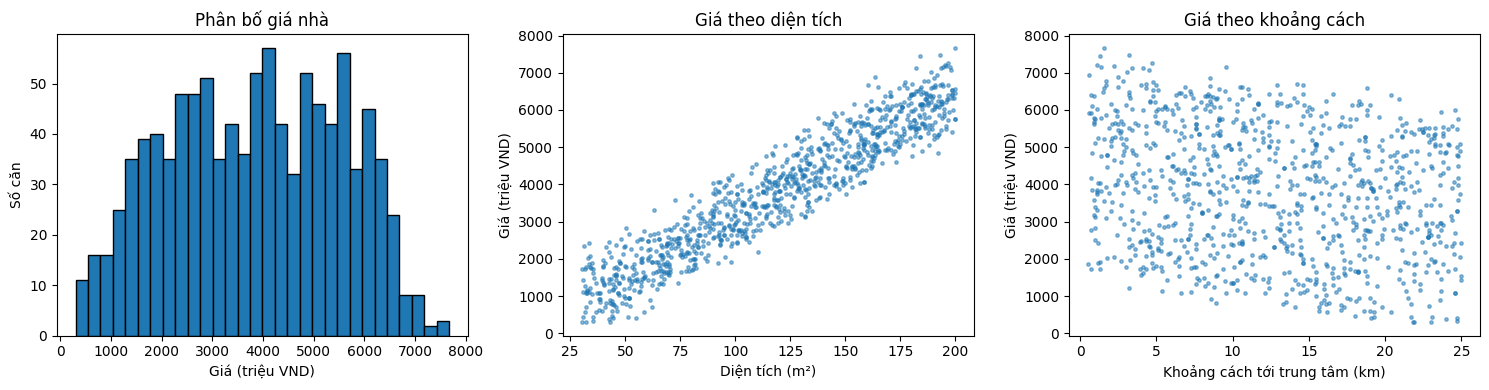

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
clean_view = raw[raw['area'] < 300]               # tạm bỏ ngoại lai để nhìn rõ
axes[0].hist(raw['price'].dropna(), bins=30, edgecolor='k')
axes[0].set_xlabel('Giá (triệu VND)'); axes[0].set_ylabel('Số căn'); axes[0].set_title('Phân bố giá nhà')
axes[1].scatter(clean_view['area'], clean_view['price'], s=6, alpha=0.5)
axes[1].set_xlabel('Diện tích (m²)'); axes[1].set_ylabel('Giá (triệu VND)'); axes[1].set_title('Giá theo diện tích')
axes[2].scatter(clean_view['distance'], clean_view['price'], s=6, alpha=0.5)
axes[2].set_xlabel('Khoảng cách tới trung tâm (km)'); axes[2].set_ylabel('Giá (triệu VND)'); axes[2].set_title('Giá theo khoảng cách')
plt.tight_layout()
plt.show()

## 2. Tiền xử lý dữ liệu và lựa chọn đặc trưng

In [3]:
df = raw.drop_duplicates().copy()                               # xóa dòng trùng
df['district'] = df['district'].str.strip().str.lower()         # thống nhất chữ viết
df = df.dropna(subset=['price'])                                # xóa dòng thiếu nhãn
df = df[df['area'].between(30, 200)]                           # miền hợp lệ từ bộ sinh, không học từ test
df['age'] = 2026 - df['year_built']                             # đặc trưng mới: tuổi nhà
print('Sau làm sạch:', df.shape)
# Quyết định giữ/loại màu sơn bằng CV trên tập train bên dưới

Sau làm sạch: (989, 8)


In [4]:
from sklearn.model_selection import train_test_split

numeric_features = ['area', 'bedrooms', 'distance', 'age']     # đặc trưng số
categorical_features = ['district']                            # đặc trưng phân loại
X = df[numeric_features + categorical_features]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Huấn luyện:', X_train.shape, ' Kiểm tra:', X_test.shape)

Huấn luyện: (791, 5)  Kiểm tra: (198, 5)


Khoảng diện tích 30–200 m² được xác định trước từ bộ sinh dữ liệu mô phỏng. Không dùng ngưỡng IQR học từ test và không áp dụng khoảng này cho nhà thực tế nói chung.

Các bước biến đổi còn lại (điền giá trị thiếu, mã hóa one-hot, chuẩn hóa) được gói vào `Pipeline`: chúng chỉ học thống kê trên tập huấn luyện, tránh rò rỉ thông tin từ tập kiểm tra.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric, categorical, scale):
    """Điền trung vị cho cột số (và chuẩn hóa nếu scale=True), mã hóa one-hot cho cột phân loại."""
    numeric_steps = [SimpleImputer(strategy='median')] + ([StandardScaler()] if scale else [])
    transformers = [('num', make_pipeline(*numeric_steps), numeric)]
    if categorical:
        transformers.append(('cat', OneHotEncoder(), categorical))
    return ColumnTransformer(transformers)

## 3. Lựa chọn mô hình học máy phù hợp

So sánh một số mô hình bằng **kiểm định chéo 5 phần** trên tập huấn luyện (chưa dùng tập kiểm tra):

- Hồi quy tuyến tính chỉ với 3 đặc trưng ban đầu (mô hình cơ sở).
- Hồi quy tuyến tính với đầy đủ đặc trưng đã thiết kế.
- Hồi quy tuyến tính thêm cả màu sơn (kiểm tra quyết định loại đặc trưng).
- k láng giềng gần nhất (k-NN) và cây quyết định (học ở Bài 6), dùng như hộp đen qua giao diện chung của scikit-learn.

In [6]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

X_train_paint = X_train.join(df['paint_color'])                 # thêm cột màu sơn để so sánh
candidates = {
    'Tuyến tính, 3 đặc trưng gốc': (make_pipeline(make_preprocessor(['area', 'bedrooms', 'distance'], [], False),
                                                  LinearRegression()), X_train),
    'Tuyến tính, đủ đặc trưng': (make_pipeline(make_preprocessor(numeric_features, categorical_features, False),
                                               LinearRegression()), X_train),
    'Tuyến tính, thêm màu sơn': (make_pipeline(make_preprocessor(numeric_features, categorical_features + ['paint_color'], False),
                                               LinearRegression()), X_train_paint),
    'k-NN (k = 10)': (make_pipeline(make_preprocessor(numeric_features, categorical_features, True),
                                    KNeighborsRegressor(n_neighbors=10)), X_train),
    'Cây quyết định (độ sâu 5)': (make_pipeline(make_preprocessor(numeric_features, categorical_features, False),
                                                DecisionTreeRegressor(max_depth=5, random_state=0)), X_train),
}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
for name, (model, X_candidate) in candidates.items():
    scores = -cross_val_score(model, X_candidate, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    print(f'{name:28s} RMSE kiểm định chéo = {scores.mean():6.1f} ± {scores.std():4.1f}')

Tuyến tính, 3 đặc trưng gốc  RMSE kiểm định chéo =  297.2 ±  9.1


Tuyến tính, đủ đặc trưng     RMSE kiểm định chéo =  255.1 ±  3.4
Tuyến tính, thêm màu sơn     RMSE kiểm định chéo =  255.8 ±  3.8


k-NN (k = 10)                RMSE kiểm định chéo =  377.9 ± 17.8
Cây quyết định (độ sâu 5)    RMSE kiểm định chéo =  392.1 ± 17.8


Hồi quy tuyến tính với đầy đủ đặc trưng cho sai số nhỏ nhất. Thêm màu sơn không cải thiện (còn hơi tệ hơn), khẳng định quyết định loại bỏ đặc trưng này. k-NN và cây quyết định kém hơn vì quan hệ trong dữ liệu chủ yếu là tuyến tính, và hai mô hình này cần nhiều dữ liệu hơn để xấp xỉ tốt.

## 4. Ước lượng tham số và xây dựng mô hình dự đoán

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model = candidates['Tuyến tính, đủ đặc trưng'][0].fit(X_train, y_train)   # huấn luyện trên toàn bộ tập huấn luyện
names = model[0].get_feature_names_out()
print('w0 =', round(model[-1].intercept_, 2))
for name, weight in zip(names, model[-1].coef_):
    print(f'{name:28s} w = {weight:8.2f}')

w0 = 541.96
num__area                    w =    29.85
num__bedrooms                w =   155.65
num__distance                w =   -35.68
num__age                     w =   -11.09
cat__district_center         w =   358.01
cat__district_outskirts      w =  -322.10
cat__district_suburb         w =   -35.91


In [8]:
y_pred = model.predict(X_test)                   # đánh giá một lần duy nhất trên tập kiểm tra
print('MAE  = %.1f triệu' % mean_absolute_error(y_test, y_pred))
print('RMSE = %.1f triệu' % np.sqrt(mean_squared_error(y_test, y_pred)))
print('R^2  = %.4f' % r2_score(y_test, y_pred))

MAE  = 188.3 triệu
RMSE = 236.3 triệu
R^2  = 0.9801


In [9]:
new_house = pd.DataFrame({'area': [100], 'bedrooms': [3], 'distance': [10],
                          'age': [2026 - 2015], 'district': ['suburb']})
print('Giá dự đoán: %.0f triệu VND' % model.predict(new_house)[0])

Giá dự đoán: 3479 triệu VND
